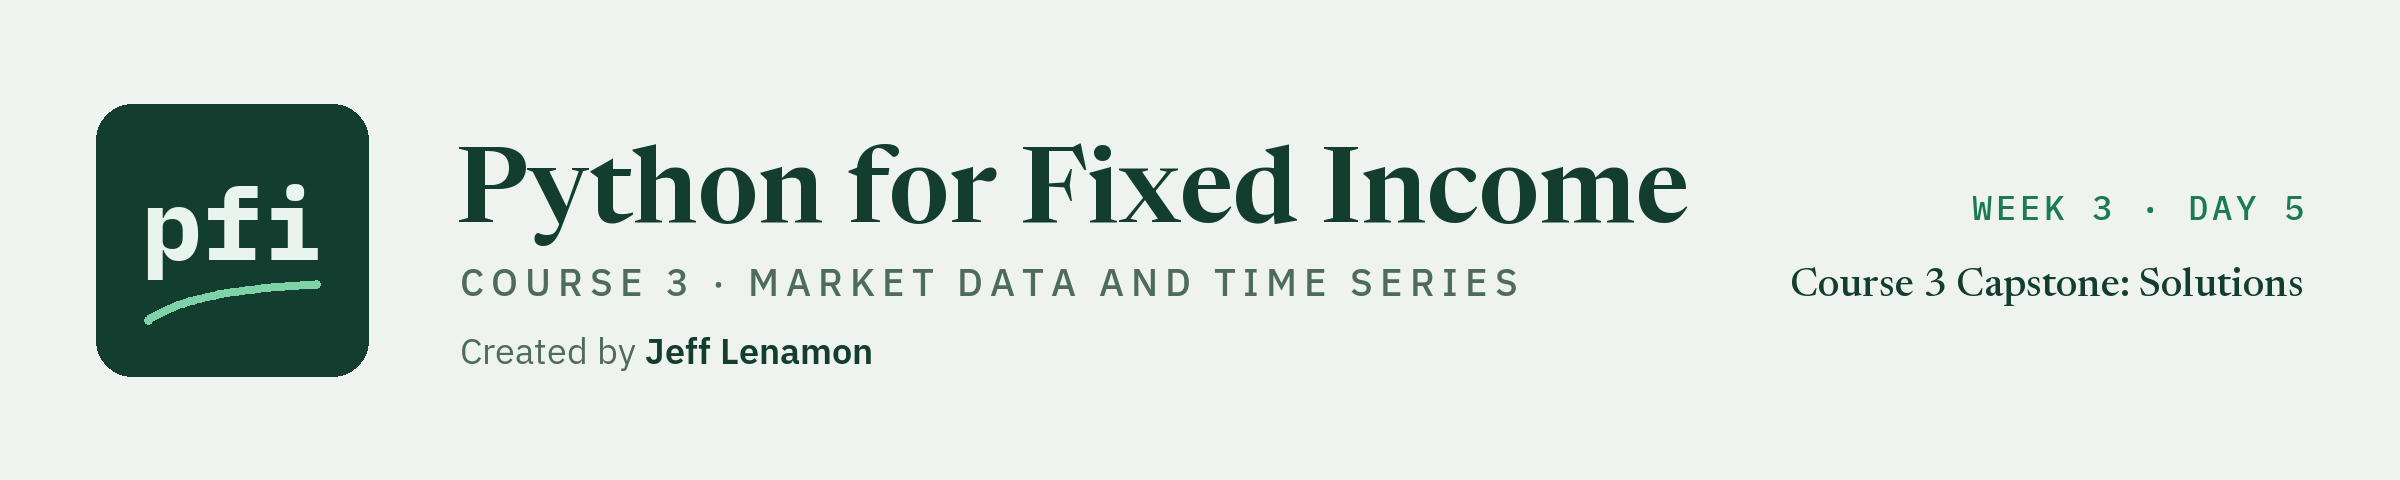

# Course 3 Capstone: Solutions

Week 3, Day 5. The worked version of the capstone: every question answered with code, its output, and what the output shows. Write your own answers and your own page first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day5/course3_capstone_solutions.ipynb)

## Setup

The same cells as the capstone notebook.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 14 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(15, after=14)

Work folder pfi_course3_15_k4w7q2xr: 10 data files, Course 2's bondmath.py, marketdata.py as notebook 14 left it, 14 commits, tagged week1 and week2


In [2]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......................................................                  [100%]
55 passed in 0.50s



In [3]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
# the module as notebook 14 left it, in the work folder
import marketdata as md

In [4]:
# raw is the extract exactly as it arrived, every cell read as text
raw = pd.read_csv('course3_capstone_extract.csv', dtype=str)
# source: the Treasury file (percent) joined to the synthetic spreads (bp), as in notebook 14
options = {'parse_dates': ['date'], 'index_col': 'date', 'float_precision': 'round_trip'}
source = pd.read_csv('treasury_par_yields.csv', **options).join(
    pd.read_csv('course3_synthetic_spreads.csv', **options), validate='one_to_one')
september = pd.read_csv('holdings.csv')

In [5]:
# the cover note's figures, typed in, and the last day of the clean history
NOTE_DAYS = 66
NOTE_LAST = {'2 Yr': 4.83, '5 Yr': 5.06, '10 Yr': 5.28, '30 Yr': 5.63,
             'ig_spread_bp': 97.0, 'hy_spread_bp': 328.7}
VALUE_COLUMNS = list(NOTE_LAST)
YIELDS, SPREADS = VALUE_COLUMNS[:4], VALUE_COLUMNS[4:]
HISTORY_END = '2026-06-30'


def headline(label, table):
    # rows, and cells with no number ('.' as sent, or NaN once read), before and after every fix
    empty = int((table == '.').sum().sum() + table.isna().sum().sum())
    print(f'{label}: {len(table)} rows, {empty} cells with no number')

In [6]:
# check() compares a fingerprint of your answer with a stored one, so no answer is written here
import hashlib


def check(label, answer, code, places=None):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    # a number is rounded to the places the question asks for, so 7 and 7.0 read the same
    if places is not None:
        answer = round(float(answer), places)
    text = label + '|' + str(answer).strip().lower()
    # hashlib.sha256() makes a fingerprint that cannot be turned back into the answer;
    # .encode() turns the text into bytes for it, and .hexdigest() writes it as letters and digits
    if hashlib.sha256(text.encode()).hexdigest()[:12] == code:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have ' + str(answer))

## 1 The File and Its Note

### 1.1 Rows, Columns, and a Working Copy

In [7]:
# shape is (rows, columns); extract is the working copy, and raw is not changed again
answer_1_1 = raw.shape
extract = raw.copy()
print(answer_1_1)

(69, 7)


In [8]:
check('Question 1.1', answer_1_1, 'cefd585c57fa')

Question 1.1: correct


69 rows where the note promises 66 market days: three rows too many before a value is read.

### 1.2 The File Against Its Note

In [9]:
headline('As received', raw)
answer_1_2a = len(raw) - NOTE_DAYS
print('columns in the note\'s order:', list(raw.columns) == ['date'] + VALUE_COLUMNS)
# the last row's six values against the note's, one by one
last_row = raw.iloc[-1]
answer_1_2b = (last_row[VALUE_COLUMNS].astype(float) != pd.Series(NOTE_LAST)).sum()
print('last row', last_row['date'], '| values that differ from the note:', answer_1_2b)

As received: 69 rows, 6 cells with no number
columns in the note's order: True
last row 2026-10-02 | values that differ from the note: 0


In [10]:
check('Question 1.2 rows', answer_1_2a, '34bb5cef5d6e', places=0)
check('Question 1.2 last row', answer_1_2b, 'f7c08b799c65', places=0)

Question 1.2 rows: correct
Question 1.2 last row: correct


The columns and the last row agree with the note; three extra rows and six empty cells do not.

## 2 Test the Extract

### 2.1 Rule 2: Dates

In [11]:
# a date that does not read as YYYY-MM-DD comes back NaT with errors='coerce'
iso = pd.to_datetime(extract['date'], format='%Y-%m-%d', errors='coerce')
answer_2_1 = iso.isna().sum()
print(extract.loc[iso.isna(), 'date'].tolist())

['07/20/2026', '08/14/2026', '09/04/2026']


In [12]:
check('Question 2.1', answer_2_1, '215a68538e6a', places=0)

Question 2.1: correct


Three dates are written month first; each reads as a weekday in the period once read that way.

### 2.2 Rule 5: No Value Missing

In [13]:
# '.' marks no value, as on FRED
dots = extract[VALUE_COLUMNS] == '.'
answer_2_2a = dots.sum().sum()
answer_2_2b = dots.any(axis=1).sum()
print(extract[dots.any(axis=1)].to_string())

          date 2 Yr 5 Yr 10 Yr 30 Yr ig_spread_bp hy_spread_bp
47  2026-09-07    .    .     .     .            .            .


In [14]:
check('Question 2.2 cells', answer_2_2a, '4abbf26e8942', places=0)
check('Question 2.2 rows', answer_2_2b, 'd541498f8e00', places=0)

Question 2.2 cells: correct
Question 2.2 rows: correct


All six `.` sit in one row, 2026-09-07, a Monday.

### 2.3 Rule 1: Copies

In [15]:
copies = extract.duplicated()
answer_2_3 = copies.sum()
print(extract[copies].to_string())

          date  2 Yr  5 Yr 10 Yr 30 Yr ig_spread_bp hy_spread_bp
52  2026-09-11  4.63  4.78  4.96  5.35         91.5        307.7
55  2026-09-15  4.67  4.83  5.00  5.36         93.9        316.0


In [16]:
check('Question 2.3', answer_2_3, '6cc3d22a07c7', places=0)

Question 2.3: correct


Two rows repeat the row above them exactly.

### 2.4 Rule 6: Units

In [17]:
# the values as numbers, '.' left out
numbers = extract[VALUE_COLUMNS].where(~dots).astype(float)
answer_2_4a = (numbers[YIELDS] > 25).sum().sum()
answer_2_4b = (numbers[SPREADS] < 10).sum().sum()
off = (numbers[YIELDS] > 25).any(axis=1) | (numbers[SPREADS] < 10).any(axis=1)
print(extract[off].to_string())

          date  2 Yr  5 Yr 10 Yr 30 Yr ig_spread_bp hy_spread_bp
22  2026-08-04  4.20   433  4.63  5.18         93.9        314.2
33  2026-08-18  4.19  4.37  4.71  5.28        0.957        327.1
43  2026-09-01  4.39   455  4.79  5.27         95.0        322.7
58  2026-09-18  4.76  4.86  5.01  5.34         96.1        3.251


In [18]:
check('Question 2.4 yields', answer_2_4a, 'b17155d3a41a', places=0)
check('Question 2.4 spreads', answer_2_4b, 'defac6353129', places=0)

Question 2.4 yields: correct
Question 2.4 spreads: correct


Two 5 Yr yields read as whole basis points, and one spread of each kind as a percent: each is a hundred times off its neighbours.

## 3 Fix the Dates and the Rows

### 3.1 Dates and Copies

**Decision.** Read each date as `YYYY-MM-DD`, else `MM/DD/YYYY`: 3 rows, and none is left unread.

Then remove the 2 exact copies, keeping the first: evidence, 2.3's rows equal the row above them in every column.

In [19]:
headline('Before', extract)
us = pd.to_datetime(extract['date'], format='%m/%d/%Y', errors='coerce')
# each date in the form it was written; a copy is now found on the read date
extract['date'] = iso.fillna(us)
extract = extract.drop_duplicates()
headline('After', extract)
answer_3_1 = len(extract)

Before: 69 rows, 6 cells with no number
After: 67 rows, 6 cells with no number


In [20]:
check('Question 3.1', answer_3_1, '5d876ff26f3b', places=0)

Question 3.1: correct


### 3.2 The Row of Dots

In [21]:
# the row with '.' in every value, and whether the market had a curve that day
empty = (extract[VALUE_COLUMNS] == '.').all(axis=1)
day = extract.loc[empty, 'date'].iloc[0]
answer_3_2a = f'{day:%Y-%m-%d}'
answer_3_2b = day in source.index
print(answer_3_2a, answer_3_2b)

2026-09-07 False


In [22]:
check('Question 3.2 date', answer_3_2a, '1f4a71c62771')
check('Question 3.2 market day', answer_3_2b, 'c3275e2fd133')

Question 3.2 date: correct
Question 3.2 market day: correct


**Decision.** Drop the row of dots, 1 row: `source` has no row for 2026-09-07, so the market printed no curve that day.

It is never read as 0.

In [23]:
headline('Before', extract)
extract = extract[~empty]
headline('After', extract)

Before: 67 rows, 6 cells with no number
After: 66 rows, 0 cells with no number


### 3.3 Rules 3 and 4: The Market's Own Days

In [24]:
dates = pd.DatetimeIndex(extract['date'])
# a date source lacks is not a market day; a market day the extract lacks is missing
answer_3_3a = f'{dates.difference(source.index)[0]:%Y-%m-%d}'
weekdays_missing = md.missing_weekdays(dates)
answer_3_3b = f'{weekdays_missing.intersection(source.index)[0]:%Y-%m-%d}'
print(answer_3_3a, '|', list(weekdays_missing.strftime('%Y-%m-%d')), '|', answer_3_3b)

2026-08-08 | ['2026-07-03', '2026-07-16', '2026-09-07'] | 2026-07-16


In [25]:
check('Question 3.3 not a market day', answer_3_3a, 'ba83ab38c9d9')
check('Question 3.3 no row', answer_3_3b, '02f18fb7688d')

Question 3.3 not a market day: correct
Question 3.3 no row: correct


**Decision.** Drop 2026-08-08, 1 row: a Saturday, so not a market day of `source`.

Of the three weekdays with no row, 2026-07-03 and 2026-09-07 have no row in `source` either; 2026-07-16 does, so it is restored in 4.3.

In [26]:
headline('Before', extract)
extract = extract[extract['date'].isin(source.index)]
headline('After', extract)

Before: 66 rows, 0 cells with no number
After: 65 rows, 0 cells with no number


## 4 Fix the Values

### 4.1 Rule 6: Units

**Decision.** A yield above 25 was sent in bp: divided by 100, to 2 decimals, 2 rows.

A spread below 10 was sent in percent: times 100, to 1 decimal, 2 rows.

Evidence: 2.4's values are a hundred times off their neighbours.

In [27]:
# dates as the index, values as floats
extract = extract.set_index('date')[VALUE_COLUMNS].astype(float)
for column in YIELDS:
    extract.loc[extract[column] > 25, column] = (extract[column] / 100).round(2)
for column in SPREADS:
    extract.loc[extract[column] < 10, column] = (extract[column] * 100).round(1)
answer_4_1a = extract[YIELDS].max().max()
answer_4_1b = extract[SPREADS].min().min()
print(answer_4_1a, answer_4_1b)

5.64 91.5


In [28]:
check('Question 4.1 largest yield', answer_4_1a, '7be835931457', places=2)
check('Question 4.1 smallest spread', answer_4_1b, 'dbda7fa3888a', places=1)

Question 4.1 largest yield: correct
Question 4.1 smallest spread: correct


### 4.2 Rule 7: A Stale Run

In [29]:
for column in VALUE_COLUMNS:
    runs = md.stale_runs(extract[column], min_length=5)
    print(column, len(runs), 'runs')
stale = md.stale_runs(extract['hy_spread_bp'], min_length=5)
print(stale.to_string())
answer_4_2a = 'hy_spread_bp'
answer_4_2b = f"{stale['start'].iloc[0]:%Y-%m-%d}"

2 Yr 0 runs
5 Yr 0 runs
10 Yr 0 runs
30 Yr 0 runs
ig_spread_bp 0 runs
hy_spread_bp 1 runs
       start        end  length  value
0 2026-07-28 2026-08-03       5  343.6


In [30]:
check('Question 4.2 column', answer_4_2a, '70e70314111f')
check('Question 4.2 start', answer_4_2b, '8a48f423d4cb')

Question 4.2 column: correct
Question 4.2 start: correct


**Decision.** In `hy_spread_bp`, 343.6 holds for 5 market days from 2026-07-28: the first value stands and the 4 repeats come from `source`.

The clean synthetic file has no run that long in either spread; with a real vendor the values would be asked for again.

### 4.3 Restore From the Source

In [31]:
# the four repeats, the first value kept
repeats = extract.loc[stale['start'].iloc[0]:stale['end'].iloc[0]].index[1:]
extract.loc[repeats, 'hy_spread_bp'] = source.loc[repeats, 'hy_spread_bp']
# the missing market day, taken whole from source, then every row in date order
missing_day = source.loc[['2026-07-16'], VALUE_COLUMNS]
extract = pd.concat([extract, missing_day]).sort_index()
assert extract.index.equals(source.loc['2026-07-01':'2026-10-02'].index), 'not the market days'
headline('After', extract)
answer_4_3 = extract.loc['2026-07-16', '10 Yr']

After: 66 rows, 0 cells with no number


In [32]:
check('Question 4.3', answer_4_3, '3df58e7128c1', places=2)

Question 4.3: correct


### Checkpoint: The Cleaned Extract

In [33]:
# the cleaned extract against the source files and the decisions the worked version made
if extract is ...:
    print('Checkpoint: not attempted yet')
else:
    check('Checkpoint rows', len(extract), '4d3783af28ef', places=0)
    check('Checkpoint first date', f'{extract.index[0]:%Y-%m-%d}', 'bd218fac6b48')
    check('Checkpoint last date', f'{extract.index[-1]:%Y-%m-%d}', '9a51dd8ab64d')
    check('Checkpoint missing values', extract.isna().sum().sum(), '3117f3c606c8', places=0)
    gap = (extract - source.loc[extract.index, VALUE_COLUMNS]).abs().max().max()
    check('Checkpoint gap from source', gap, '8b80901df176', places=9)
    check('Checkpoint mean 5 Yr', extract['5 Yr'].mean(), '865b6d2992f1', places=3)
    check('Checkpoint mean hy', extract['hy_spread_bp'].mean(), '8ea3cb50eb1d', places=3)
    check('Checkpoint raw is unchanged', raw.shape, 'd0733f5fa2a6')

Checkpoint rows: correct
Checkpoint first date: correct
Checkpoint last date: correct
Checkpoint missing values: correct
Checkpoint gap from source: correct
Checkpoint mean 5 Yr: correct
Checkpoint mean hy: correct
Checkpoint raw is unchanged: correct


66 market days, none empty, and not one value apart from the source files.

## 5 Package It

### 5.1 `clean_extract`, Docstring First

In [34]:
%%writefile clean_extract.py
"""clean_extract: the desk's decisions for the vendor's daily extract, from the Course 3 capstone.

Units: yields in percent, spreads in bp, as the cover note states. The market calendar is the clean
source's own dates, never a holiday list.
"""
import pandas as pd

import marketdata as md

VALUE_COLUMNS = ['2 Yr', '5 Yr', '10 Yr', '30 Yr', 'ig_spread_bp', 'hy_spread_bp']
YIELDS = VALUE_COLUMNS[:4]
SPREADS = VALUE_COLUMNS[4:]


def _note(log, day, column, received, cleaned, decision):
    """Add one line to the log, every value as text (a helper, not part of the API)."""
    log.append({'date': f'{day:%Y-%m-%d}', 'column': column, 'received': str(received),
                'cleaned': str(cleaned), 'decision': decision})


def clean_extract(raw, source):
    """One row per market day of the extract's period, from the extract as it arrived.

    raw: the extract as read, every cell text. source: the clean history (the Treasury file joined to
    the synthetic spreads), whose dates are the market calendar. Neither is changed.
    The decisions, in order:
      1. A date is read as YYYY-MM-DD, else as MM/DD/YYYY.
      2. An exact copy of a row is removed, keeping the first.
      3. '.' is a missing value, never 0. A row with every value missing goes, if no market day.
      4. A row dated on a day that is not a market day of source goes.
      5. A yield above 25 was sent in bp: divided by 100, to 2 decimals.
         A spread below 10 was sent in percent: times 100, to 1 decimal.
      6. A stale run, 5 or more equal values in a row: the first stands, each repeat from source.
      7. A market day with no row is restored from source, never filled from a neighbour.
    Returns (cleaned, log). cleaned: the dates as its index, VALUE_COLUMNS as floats.
    log: one row per change, with date (YYYY-MM-DD), column ('all' for a whole row), received,
    cleaned, and decision.
    """
    log = []
    extract = raw.copy()
    # 1: each date read in the form it was written
    iso = pd.to_datetime(extract['date'], format='%Y-%m-%d', errors='coerce')
    us = pd.to_datetime(extract['date'], format='%m/%d/%Y', errors='coerce')
    for i in extract.index[iso.isna() & us.notna()]:
        _note(log, us[i], 'date', extract.loc[i, 'date'], f'{us[i]:%Y-%m-%d}', 'date written MM/DD/YYYY')
    extract['date'] = iso.fillna(us)
    assert extract['date'].notna().all(), 'a date in neither form'
    # 2: exact copies, compared once the dates are read
    copies = extract.duplicated()
    for day in extract.loc[copies, 'date']:
        _note(log, day, 'all', 'the row twice', 'one row', 'exact copy removed')
    extract = extract[~copies]
    # 3: '.' is no value; a row with nothing in it goes if the market had no curve that day
    empty = (extract[VALUE_COLUMNS] == '.').all(axis=1)
    for day in extract.loc[empty, 'date']:
        assert day not in source.index, f'{day:%Y-%m-%d} is a market day with every value missing'
        _note(log, day, 'all', "'.' in every value", 'no row', 'no market that day, row dropped')
    extract = extract[~empty]
    assert not (extract[VALUE_COLUMNS] == '.').any().any(), 'a value is missing in a row with others'
    # 4: the market calendar is the source's dates
    for day in extract.loc[~extract['date'].isin(source.index), 'date']:
        _note(log, day, 'all', 'a row', 'no row', 'not a market day, row dropped')
    extract = extract[extract['date'].isin(source.index)]
    cleaned = extract.set_index('date')[VALUE_COLUMNS].astype(float)
    # 5: units, by the cover note's thresholds
    for column in YIELDS:
        for day in cleaned.index[cleaned[column] > 25]:
            fixed = round(cleaned.loc[day, column] / 100, 2)
            _note(log, day, column, cleaned.loc[day, column], fixed, 'yield sent in bp, / 100')
            cleaned.loc[day, column] = fixed
    for column in SPREADS:
        for day in cleaned.index[cleaned[column] < 10]:
            fixed = round(cleaned.loc[day, column] * 100, 1)
            _note(log, day, column, cleaned.loc[day, column], fixed, 'spread sent in percent, x 100')
            cleaned.loc[day, column] = fixed
    # 6: a stale run keeps its first value; each repeat comes from source
    for column in VALUE_COLUMNS:
        for run in md.stale_runs(cleaned[column], min_length=5).itertuples():
            for day in cleaned.loc[run.start:run.end].index[1:]:
                _note(log, day, column, cleaned.loc[day, column], source.loc[day, column],
                      'stale repeat, restored from source')
                cleaned.loc[day, column] = source.loc[day, column]
    # 7: a market day with no row comes from source, never from the day before
    market_days = source.loc[cleaned.index[0]:cleaned.index[-1]].index
    missing = market_days.difference(cleaned.index)
    for day in missing:
        _note(log, day, 'all', 'no row', 'the row from source', 'missing market day, from source')
    cleaned = pd.concat([cleaned, source.loc[missing, VALUE_COLUMNS]]).sort_index()
    # the promises, tested before the table goes back
    assert cleaned.index.equals(market_days), 'the dates are not the market days of the period'
    assert cleaned.notna().all().all(), 'a value is missing'
    assert (cleaned[YIELDS] <= 25).all().all(), 'a yield is still above 25'
    assert (cleaned[SPREADS] >= 10).all().all(), 'a spread is still below 10'
    for column in VALUE_COLUMNS:
        assert md.stale_runs(cleaned[column], min_length=5).empty, f'{column} has a stale run'
    log = pd.DataFrame(log, columns=['date', 'column', 'received', 'cleaned', 'decision'])
    return cleaned, log.sort_values(['date', 'column'], ignore_index=True)

Writing clean_extract.py


In [35]:
from clean_extract import clean_extract

cleaned, log = clean_extract(raw, source)
# the cover note's market days and last values
assert len(cleaned) == NOTE_DAYS, 'not the note\'s market days'
assert (cleaned.iloc[-1] == pd.Series(NOTE_LAST)).all(), 'the last row differs from the note'
print(log.to_string())

          date        column            received              cleaned                            decision
0   2026-07-16           all              no row  the row from source     missing market day, from source
1   2026-07-20          date          07/20/2026           2026-07-20             date written MM/DD/YYYY
2   2026-07-29  hy_spread_bp               343.6                333.3  stale repeat, restored from source
3   2026-07-30  hy_spread_bp               343.6                332.9  stale repeat, restored from source
4   2026-07-31  hy_spread_bp               343.6                327.1  stale repeat, restored from source
5   2026-08-03  hy_spread_bp               343.6                320.3  stale repeat, restored from source
6   2026-08-04          5 Yr               433.0                 4.33             yield sent in bp, / 100
7   2026-08-08           all               a row               no row       not a market day, row dropped
8   2026-08-14          date          08/14/20

In [36]:
check('Question 5.1 rows', len(cleaned), '61ed9e1e2e21', places=0)
check('Question 5.1 same as extract', cleaned.equals(extract), '288c3cca9e6d')
check('Question 5.1 log lines', len(log), '9f174ecd8344', places=0)
check('Question 5.1 raw is unchanged', raw.shape, '99d973544a52')

Question 5.1 rows: correct
Question 5.1 same as extract: correct
Question 5.1 log lines: correct
Question 5.1 raw is unchanged: correct


Sixteen changes, each a line with its decision; `cleaned` is the checkpoint's `extract`, made by one call.

### As Received Against Cleaned

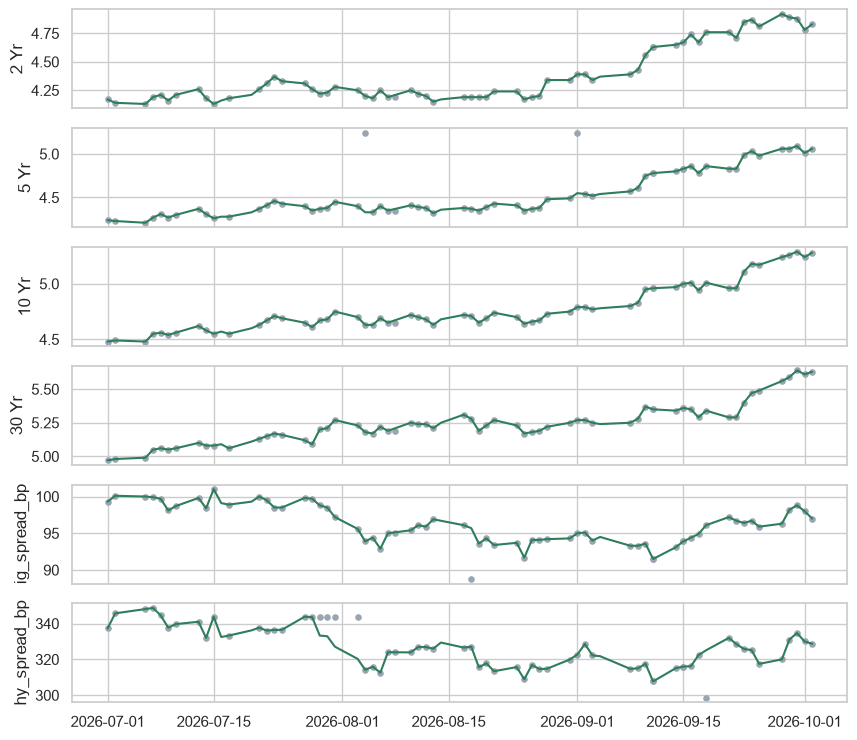

In [37]:
# written for you: each column as received (grey points) against cleaned (green line)
if cleaned is not ...:
    # the dates written YYYY-MM-DD; the three month-first rows are left out, their values clean
    dates = pd.to_datetime(raw['date'], format='%Y-%m-%d', errors='coerce')
    fig, axes = plt.subplots(6, 1, figsize=(10, 9), sharex=True)
    for ax, column in zip(axes, VALUE_COLUMNS):
        # clip(low, high), Course 1's clip at both ends: a value sent far off sits on the edge
        low, high = cleaned[column].min() * 0.97, cleaned[column].max() * 1.03
        sent = pd.to_numeric(raw[column], errors='coerce').clip(low, high)
        ax.scatter(dates, sent, s=14, color='#9AA5B1')
        ax.plot(cleaned.index, cleaned[column], color='#2E7D5B')
        ax.set_ylabel(column)
    plt.show()

### 5.2 Commit It

In [38]:
!git -C "{work}" status --short
!git -C "{work}" add clean_extract.py
!git -C "{work}" commit -q -m "Capstone: clean_extract and its seven decisions"
!git -C "{work}" log --oneline -3

?? clean_extract.py
16e6b59 Capstone: clean_extract and its seven decisions
e8c66e0 Notebook 14: snapshot_tables, write_snapshot_html, write_snapshot_excel, and snapshot.py
d3b19f3 Notebook 13: parse_json_reply


## 6 The Reconciliation

### 6.1 The File Against the Source

In [39]:
# the file as received, its dates read in both forms, nothing else fixed
received = raw.copy()
received['date'] = pd.to_datetime(raw['date'], format='%Y-%m-%d', errors='coerce').fillna(
    pd.to_datetime(raw['date'], format='%m/%d/%Y', errors='coerce'))
period = source.loc['2026-07-01':'2026-10-02', VALUE_COLUMNS]
rows = []
# whole rows: each extra copy, each row on a day with no market, each market day with no row
for day in received.loc[received.duplicated(), 'date']:
    rows.append({'date': day, 'column': 'all', 'received': 'a copy', 'source': 'one row'})
for day in received.loc[~received['date'].isin(period.index), 'date']:
    rows.append({'date': day, 'column': 'all', 'received': 'a row', 'source': 'no row'})
for day in period.index.difference(received['date']):
    rows.append({'date': day, 'column': 'all', 'received': 'no row', 'source': 'a row'})
# values: each market-day row, as a number, against source
values = received.drop_duplicates().set_index('date')
values = values.loc[values.index.isin(period.index), VALUE_COLUMNS].astype(float)
for column in VALUE_COLUMNS:
    for day in values.index[values[column] != period.loc[values.index, column]]:
        rows.append({'date': day, 'column': column, 'received': str(values.loc[day, column]),
                     'source': str(period.loc[day, column])})
differences = pd.DataFrame(rows)
differences['date'] = differences['date'].dt.strftime('%Y-%m-%d')
answer_6_1 = len(differences)
print(differences.to_string())

          date        column received   source
0   2026-09-11           all   a copy  one row
1   2026-09-15           all   a copy  one row
2   2026-08-08           all    a row   no row
3   2026-09-07           all    a row   no row
4   2026-07-16           all   no row    a row
5   2026-08-04          5 Yr    433.0     4.33
6   2026-09-01          5 Yr    455.0     4.55
7   2026-08-18  ig_spread_bp    0.957     95.7
8   2026-07-29  hy_spread_bp    343.6    333.3
9   2026-07-30  hy_spread_bp    343.6    332.9
10  2026-07-31  hy_spread_bp    343.6    327.1
11  2026-08-03  hy_spread_bp    343.6    320.3
12  2026-09-18  hy_spread_bp    3.251    325.1


In [40]:
check('Question 6.1', answer_6_1, '3457608b9905', places=0)

Question 6.1: correct


Thirteen differences: eight values, two copies, two rows on days with no market, one market day with no row.

The three month-first dates make none once read.

### 6.2 A Decision for Every Difference

In [41]:
# each difference finds its log line on date and column; a log key appears once
explained = differences.merge(log[['date', 'column', 'decision']], on=['date', 'column'],
                              how='left', validate='many_to_one')
answer_6_2a = explained['decision'].isna().sum()
answer_6_2b = explained['decision'].nunique()
print(explained['decision'].value_counts().to_string())

decision
stale repeat, restored from source    4
exact copy removed                    2
yield sent in bp, / 100               2
spread sent in percent, x 100         2
not a market day, row dropped         1
no market that day, row dropped       1
missing market day, from source       1


In [42]:
check('Question 6.2 unexplained', answer_6_2a, '127b5cf28a78', places=0)
check('Question 6.2 decisions', answer_6_2b, '49c249660466', places=0)

Question 6.2 unexplained: correct
Question 6.2 decisions: correct


None without a decision; seven of the log's eight decisions carry them, and the eighth, the month-first dates, changed nothing a reader of the values sees.

### Every Difference by Its Decision

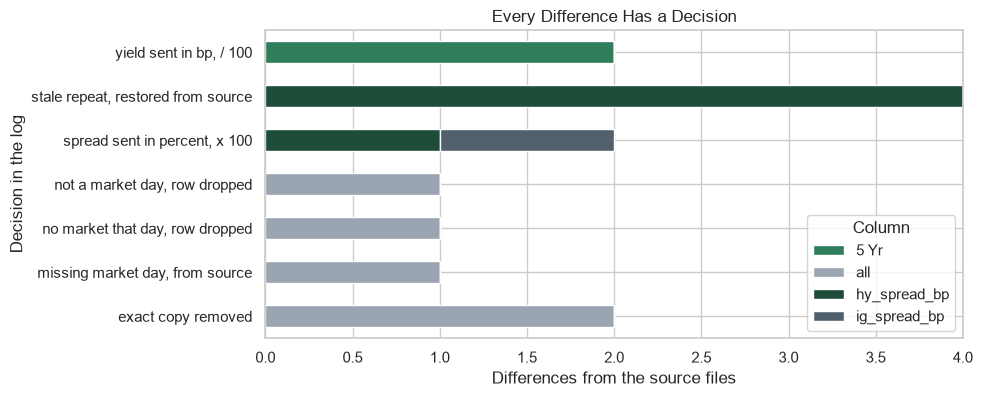

In [43]:
# written for you: each decision's differences, split by column (Course 1's crosstab)
if explained is ...:
    print('Chart: not attempted yet')
else:
    by_decision = pd.crosstab(explained['decision'], explained['column'])
    ax = by_decision.plot.barh(stacked=True, figsize=(9, 4))
    ax.set_title('Every Difference Has a Decision')
    ax.set_xlabel('Differences from the source files')
    ax.set_ylabel('Decision in the log')
    ax.legend(title='Column')
    plt.show()

## 7 Append, Then the Snapshot

### 7.1 The Appended Market

In [44]:
# the clean history to the day before the extract, then the cleaned extract
market = pd.concat([source.loc[:HISTORY_END], cleaned])
assert market.index.is_unique and market.index.is_monotonic_increasing, 'dates repeat or disorder'
# every column the extract carries equals the source files, on every row
pd.testing.assert_frame_equal(market[VALUE_COLUMNS], source[VALUE_COLUMNS], check_exact=True)
answer_7_1 = len(market)
from_july = market.loc['2026-07-01':, '3 Mo'].notna().sum()
print(answer_7_1, 'rows;', from_july, '3 Mo values from July')

2940 rows; 0 3 Mo values from July


In [45]:
check('Question 7.1', answer_7_1, '471d9de65069', places=0)

Question 7.1: correct


2,940 rows, the Treasury file's own count, and the ten tenors the extract does not carry are empty from July.

### 7.2 The Snapshot for 2 October

In [46]:
# the levels table's columns and their units, as notebook 14's
units = {'2 Yr': 'pct', '5 Yr': 'pct', '10 Yr': 'pct', '30 Yr': 'pct',
         'ig_spread_bp': 'bp', 'hy_spread_bp': 'bp'}
tables = md.snapshot_tables(market, september, '2026-10-02', units)
answer_7_2a = len(tables['curve'])
answer_7_2b = tables['slopes_flies'].loc['3m10y', 'level']
print('last 3 Mo:', f"{market['3 Mo'].dropna().index[-1]:%Y-%m-%d}")
print(tables['slopes_flies'].round(2).to_string())

last 3 Mo: 2026-06-30
         unit  level  chg_1d_bp  chg_1w_bp  chg_1m_bp  zscore  pct_rank
series                                                                 
2s10s      bp   45.0       -1.0        9.0        5.0   -0.51     28.17
5s30s      bp   57.0       -3.0        6.0      -16.0   -2.07      5.95
3m10y      bp   57.0        6.0        0.0        0.0    0.74     72.62
2s5s10s    bp    1.0        1.0        3.0       11.0    2.70     98.81
5s10s30s   bp  -13.0        1.0        0.0       10.0    2.58    100.00


In [47]:
check('Question 7.2 tenors', answer_7_2a, '16ca53503dc3', places=0)
check('Question 7.2 3m10y', answer_7_2b, '6303ca0db272', places=1)

Question 7.2 tenors: correct
Question 7.2 3m10y: correct


Predict 2 is C. `summary_table` drops each column's missing values and takes the as-of value (notebook 10), so 3m10y shows 30 June's 57 bp.
Its day change is 30 June against 29 June, and its week and month changes are zero: every figure in the row is June's, none of 2 October.

### 7.3 The Book on Four Tenors

In [48]:
# the same book and day on the Treasury file's whole curve: notebook 14's numbers
whole_curve = md.snapshot_tables(source, september, '2026-10-02', units)
answer_7_3a = tables['book'].iloc[-1]['mv_change_usd']
answer_7_3b = tables['book'].iloc[-1]['dv01_usd']
print(f"four tenors {answer_7_3a:,.2f} | "
      f"whole curve {whole_curve['book'].iloc[-1]['mv_change_usd']:,.2f}")
print(f'DV01 {answer_7_3b:,.2f} dollars per bp')

four tenors -1,179,287.02 | whole curve -1,193,297.89
DV01 306,996.11 dollars per bp


In [49]:
check('Question 7.3 what-if', answer_7_3a, '577abdf89bfa', places=2)
check('Question 7.3 DV01', answer_7_3b, '0b506ae3c452', places=2)

Question 7.3 what-if: correct
Question 7.3 DV01: correct


Predict 3 is B, 14,010.87 dollars smaller in size.
The DV01 is the same, since it reads the book's own yields.
The what-if reads the day's change at each maturity from a line through four tenors, not through every tenor of the Treasury file.

### 7.4 `snapshot.py`, Rewritten

In [50]:
%%writefile snapshot.py
"""snapshot.py: write the daily market snapshot for one market date, as HTML and as Excel.

Usage, from any folder:
    python snapshot.py --as-of 2026-10-02
    python snapshot.py                      (the last date in the market data)

It reads the Treasury file and the synthetic spreads to HISTORY_END, appends the vendor's extract cleaned by
clean_extract, and reads the synthetic book, all from the folder this file is in. It writes
snapshots/snapshot_YYYY-MM-DD.html and .xlsx there, with a notes table on what the page cannot show.
It describes the data and forecasts nothing.
"""
import argparse
from pathlib import Path

import pandas as pd
from matplotlib.figure import Figure

import marketdata as md
from clean_extract import clean_extract

# the folder this file is in, whichever folder the script is started from
HERE = Path(__file__).resolve().parent
# the market columns on the levels table, and their units
UNITS = {"2 Yr": "pct", "5 Yr": "pct", "10 Yr": "pct", "30 Yr": "pct", "ig_spread_bp": "bp", "hy_spread_bp": "bp"}
# the last day of the clean history: the extract starts on the next market day
HISTORY_END = "2026-06-30"


def load_market() -> pd.DataFrame:
    """The clean history to HISTORY_END, then the vendor's extract cleaned by clean_extract.

    The history is the Treasury file (percent) joined to the synthetic spreads (bp). After HISTORY_END only
    the extract's four tenors and two spreads have values.
    """
    options = {"parse_dates": ["date"], "index_col": "date", "float_precision": "round_trip"}
    treasury = pd.read_csv(HERE / "treasury_par_yields.csv", **options)
    spreads = pd.read_csv(HERE / "course3_synthetic_spreads.csv", **options)
    source = treasury.join(spreads, validate="one_to_one")
    raw = pd.read_csv(HERE / "course3_capstone_extract.csv", dtype=str)
    cleaned, _ = clean_extract(raw, source)
    return pd.concat([source.loc[:HISTORY_END], cleaned])


def daily_snapshot(market: pd.DataFrame, book: pd.DataFrame, as_of) -> dict[str, pd.DataFrame]:
    """md.snapshot_tables for as_of, less each shape with a tenor that has no value that day, plus notes.

    A slope or fly is dropped when a tenor it uses has no value on as_of: its as-of value would be its last
    before the gap, not a level of this date. notes, one column note, says which tenors the curve has, which
    shapes are not shown, that the book's change in value is a what-if, and that the spreads are synthetic.
    """
    tables = md.snapshot_tables(market, book, as_of, UNITS)
    stamp = tables["levels"].attrs["as_of"]
    day = market.loc[pd.Timestamp(stamp)]
    dropped = [name for name, legs in (md.SLOPES | md.FLIES).items() if day[list(legs)].isna().any()]
    tables["slopes_flies"] = tables["slopes_flies"].drop(index=dropped)
    notes = [f"Curve: the tenors with a value on {stamp} are {', '.join(tables['curve'].index)}."]
    if dropped:
        notes.append(f"Not shown: {', '.join(dropped)}, which uses a tenor with no value on {stamp}.")
    notes.append("Book: the September book (synthetic). Its change in market value is a what-if: each bond's "
                 "yield moved by the day's curve change at its maturity, interpolated between the curve's "
                 "tenors. It is not a forecast.")
    notes.append("Credit spreads: synthetic, invented for this course; not ICE, Moody's, or any index.")
    tables["notes"] = pd.DataFrame({"note": notes})
    for table in tables.values():
        table.attrs["as_of"] = stamp
    return tables


def charts(tables: dict[str, pd.DataFrame], market: pd.DataFrame) -> dict[str, Figure]:
    """The two charts, drawn without a screen: the curve on both days, and the synthetic spreads."""
    as_of = pd.Timestamp(tables["levels"].attrs["as_of"])
    previous = market.index[market.index.get_loc(as_of) - 1]
    curve = tables["curve"]
    curve_figure = Figure(figsize=(7, 3.5))
    axes = curve_figure.subplots()
    axes.plot(curve["years"], curve["previous_pct"], marker="o", markersize=3, label=f"{previous:%Y-%m-%d}")
    axes.plot(curve["years"], curve["as_of_pct"], marker="o", markersize=3, label=f"{as_of:%Y-%m-%d}")
    axes.set_title(f"Treasury par curve, {as_of:%Y-%m-%d} and the previous market date")
    axes.set_xlabel("Tenor (years)")
    axes.set_ylabel("Yield (percent)")
    axes.legend()
    curve_figure.tight_layout()

    recent = market.loc[:as_of, ["ig_spread_bp", "hy_spread_bp"]].tail(252)
    spread_figure = Figure(figsize=(7, 3.5))
    axes = spread_figure.subplots()
    axes.plot(recent.index, recent["ig_spread_bp"], label="Investment grade (synthetic)")
    axes.plot(recent.index, recent["hy_spread_bp"], label="High yield (synthetic)")
    axes.set_title("Synthetic credit spreads, the last 252 market days (invented, not an index)")
    axes.set_ylabel("Spread (bp)")
    axes.legend()
    spread_figure.autofmt_xdate()
    spread_figure.tight_layout()
    return {"Treasury curve": curve_figure, "Synthetic credit spreads": spread_figure}


def main() -> None:
    parser = argparse.ArgumentParser(description="Write the daily market snapshot as HTML and Excel.")
    parser.add_argument("--as-of", help="the market date, YYYY-MM-DD (default: the last date in the market data)")
    args = parser.parse_args()

    market = load_market()
    book = pd.read_csv(HERE / "holdings.csv")
    as_of = args.as_of or f"{market.index[-1]:%Y-%m-%d}"
    try:
        tables = daily_snapshot(market, book, as_of)
    except ValueError as error:
        # a one-line message and exit code 2, with no traceback: a traceback would print this file's full path
        parser.error(str(error))

    # the date as the tables carry it, YYYY-MM-DD, names both files
    as_of = tables["levels"].attrs["as_of"]
    out = HERE / "snapshots"
    out.mkdir(exist_ok=True)
    md.write_snapshot_html(tables, charts(tables, market), out / f"snapshot_{as_of}.html", f"Daily market snapshot, {as_of}")
    md.write_snapshot_excel(tables, out / f"snapshot_{as_of}.xlsx")
    print(f"snapshot for {as_of}: wrote snapshots/snapshot_{as_of}.html and snapshots/snapshot_{as_of}.xlsx")


if __name__ == "__main__":
    main()

Overwriting snapshot.py


In [51]:
import snapshot

check_tables = snapshot.daily_snapshot(snapshot.load_market(), september, '2026-10-02')
shown = check_tables['slopes_flies'].index
answer_7_4 = [name for name in md.SLOPES | md.FLIES if name not in shown]
print('\n'.join(check_tables['notes']['note']))

Curve: the tenors with a value on 2026-10-02 are 2 Yr, 5 Yr, 10 Yr, 30 Yr.
Not shown: 3m10y, which uses a tenor with no value on 2026-10-02.
Book: the September book (synthetic). Its change in market value is a what-if: each bond's yield moved by the day's curve change at its maturity, interpolated between the curve's tenors. It is not a forecast.
Credit spreads: synthetic, invented for this course; not ICE, Moody's, or any index.


In [52]:
check('Question 7.4', answer_7_4, '5647e31242a5')

Question 7.4: correct


### Read the Diff, Then Commit

In [53]:
!git -C "{work}" diff --stat
!git -C "{work}" add snapshot.py
!git -C "{work}" commit -q -m "Capstone: snapshot.py on the appended market, with a notes table"
!git -C "{work}" log --oneline -2

 snapshot.py | 47 ++++++++++++++++++++++++++++++++++++++++++-----
 1 file changed, 42 insertions(+), 5 deletions(-)
dcb59b8 Capstone: snapshot.py on the appended market, with a notes table
16e6b59 Capstone: clean_extract and its seven decisions


## 8 Rerun, Do Not Redo

### 8.1 Two Dates, One Command

In [54]:
# the script once per date, as Task Scheduler would start it
for as_of in ['2026-10-02', '2026-09-30']:
    result = subprocess.run([sys.executable, 'snapshot.py', '--as-of', as_of],
                            capture_output=True, text=True)
    assert result.returncode == 0, result.stderr
    print(result.returncode, result.stdout.strip())

0 snapshot for 2026-10-02: wrote snapshots/snapshot_2026-10-02.html and snapshots/snapshot_2026-10-02.xlsx
0 snapshot for 2026-09-30: wrote snapshots/snapshot_2026-09-30.html and snapshots/snapshot_2026-09-30.xlsx


In [55]:
# the 2 October page read back as text
page = Path('snapshots/snapshot_2026-10-02.html').read_text(encoding='utf-8')
print('As of 2026-10-02.' in page, md.DISCLAIMER in page, 'synthetic' in page,
      page.count('<table'), 'tables')
# the 30 September workbook, every sheet
workbook = pd.read_excel('snapshots/snapshot_2026-09-30.xlsx', sheet_name=None, index_col=0)
answer_8_1a = list(workbook.keys())
answer_8_1b = workbook['levels'].loc['10 Yr', 'level']
print(answer_8_1a, answer_8_1b)

True True True 5 tables
['about', 'levels', 'curve', 'slopes_flies', 'book', 'notes'] 5.29


In [56]:
check('Question 8.1 sheets', answer_8_1a, 'bd746f2eb678')
check('Question 8.1 10 Yr', answer_8_1b, '485231e5ab23', places=2)

Question 8.1 sheets: correct
Question 8.1 10 Yr: correct


Both runs exit with 0; the page carries its date, the disclaimer and the synthetic label, and five tables, `notes` the fifth.

### 8.2 The Two Levels Side by Side

In [57]:
first = pd.read_excel('snapshots/snapshot_2026-09-30.xlsx', sheet_name='levels', index_col=0)
second = pd.read_excel('snapshots/snapshot_2026-10-02.xlsx', sheet_name='levels', index_col=0)
two_dates = pd.DataFrame({'2026-09-30': first['level'], '2026-10-02': second['level']})
# the change in the series' own units, then the yields from percent to bp
two_dates['change_bp'] = two_dates['2026-10-02'] - two_dates['2026-09-30']
two_dates.loc[YIELDS, 'change_bp'] = two_dates.loc[YIELDS, 'change_bp'] * 100
answer_8_2 = two_dates['change_bp'].abs().idxmax()
print(two_dates.round(2).to_string())

              2026-09-30  2026-10-02  change_bp
series                                         
2 Yr                4.88        4.83       -5.0
5 Yr                5.09        5.06       -3.0
10 Yr               5.29        5.28       -1.0
30 Yr               5.64        5.63       -1.0
ig_spread_bp       98.80       97.00       -1.8
hy_spread_bp      334.70      328.70       -6.0


In [58]:
check('Question 8.2', answer_8_2, '4ba52149e161')

Question 8.2: correct


### Two Dates, Six Series

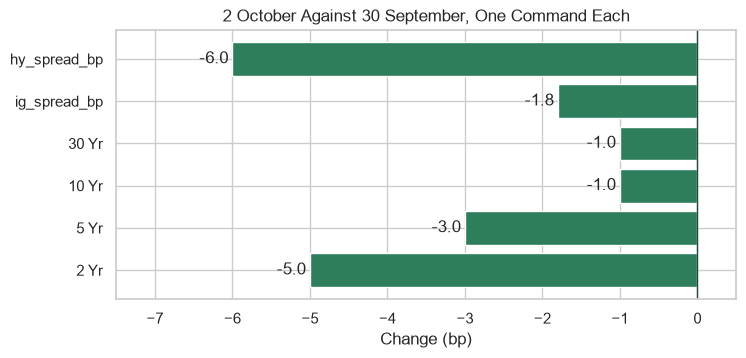

In [59]:
# written for you: each series' change from 30 September to 2 October, in bp, signed
if two_dates is ...:
    print('Chart: not attempted yet')
else:
    fig, ax = plt.subplots(figsize=(8, 3.5))
    bars = ax.barh(two_dates.index, two_dates['change_bp'])
    ax.axvline(0, color='#1E4D3A', linewidth=1)
    ax.bar_label(bars, fmt='{:+.1f}', padding=3)
    # room on both sides for the labels
    ax.set_xlim(two_dates['change_bp'].min() - 1.5, two_dates['change_bp'].max() + 1.5)
    ax.set_title('2 October Against 30 September, One Command Each')
    ax.set_xlabel('Change (bp)')
    plt.show()

Every series is lower on 2 October than on 30 September, the high yield spread by the most.

### 8.3 Both Days in the Database

In [60]:
# both levels sheets, stacked, each row with its date
history = pd.concat([first.assign(as_of='2026-09-30'), second.assign(as_of='2026-10-02')])
history = history.reset_index()[['as_of', 'series', 'unit', 'level']]
history.to_csv('snapshot_history.csv', index=False)
counts = md.load_tables(Path('course3.db'), {'snapshot_history': Path('snapshot_history.csv')})
answer_8_3a = counts['snapshot_history']
print(counts)

{'snapshot_history': 12}


In [61]:
%%writefile -a queries.sql

-- one series on every snapshot date
SELECT as_of, series, level
FROM snapshot_history
WHERE series = ?
ORDER BY as_of;

-- each series' change in bp from the snapshot before; yields are in percent
SELECT as_of, series,
       (level - LAG(level) OVER (PARTITION BY series ORDER BY as_of))
       * CASE WHEN unit = 'pct' THEN 100 ELSE 1 END AS change_bp
FROM snapshot_history
ORDER BY series, as_of;

Appending to queries.sql


In [62]:
# the first query against pandas
one_series = md.run_query(Path('course3.db'), '''
    SELECT as_of, series, level FROM snapshot_history
    WHERE series = ? ORDER BY as_of''', ('10 Yr',))
ten_year = history[history['series'] == '10 Yr'][['as_of', 'series', 'level']]
md.assert_same_rows(one_series, ten_year, ['as_of'])
print(one_series.to_string())

        as_of series  level
0  2026-09-30  10 Yr   5.29
1  2026-10-02  10 Yr   5.28


In [63]:
# the second query against pandas
change_sql = md.run_query(Path('course3.db'), '''
    SELECT as_of, series,
           (level - LAG(level) OVER (PARTITION BY series ORDER BY as_of))
           * CASE WHEN unit = 'pct' THEN 100 ELSE 1 END AS change_bp
    FROM snapshot_history ORDER BY series, as_of''')
change_pandas = history.sort_values(['series', 'as_of']).copy()
# groupby(...)['level'].diff(): each level less the one before it in the same series
# .map() with a dict, Course 1's: each row's unit as its multiplier, 100 for percent, 1 for bp
change_pandas['change_bp'] = (change_pandas.groupby('series')['level'].diff()
                              * change_pandas['unit'].map({'pct': 100, 'bp': 1}))
md.assert_same_rows(change_sql, change_pandas[['as_of', 'series', 'change_bp']],
                    ['series', 'as_of'])
high_yield = change_sql[change_sql['series'] == 'hy_spread_bp']
answer_8_3b = high_yield['change_bp'].iloc[-1]
print(answer_8_3b)

-6.0


In [64]:
check('Question 8.3 rows', answer_8_3a, '386f170975c2', places=0)
check('Question 8.3 change', answer_8_3b, 'e1e01769952b', places=1)

Question 8.3 rows: correct
Question 8.3 change: correct


Twelve rows, both queries equal to pandas, and SQL's high yield change is 8.2's.

### 8.4 A Test, Then Commit

In [65]:
%%writefile test_capstone.py
"""Tests of the capstone: the cleaned extract ties to the vendor's cover note, and the appended market
equals the source files on every column the extract carries."""
from pathlib import Path

import pandas as pd

import snapshot
from clean_extract import VALUE_COLUMNS, clean_extract

# the folder this file is in: the data files sit beside it
HERE = Path(__file__).resolve().parent
OPTIONS = {"parse_dates": ["date"], "index_col": "date", "float_precision": "round_trip"}


def read_source():
    """The Treasury file joined to the synthetic spreads, as the capstone reads them."""
    treasury = pd.read_csv(HERE / "treasury_par_yields.csv", **OPTIONS)
    spreads = pd.read_csv(HERE / "course3_synthetic_spreads.csv", **OPTIONS)
    return treasury.join(spreads, validate="one_to_one")


def test_clean_extract_ties_to_the_cover_note():
    raw = pd.read_csv(HERE / "course3_capstone_extract.csv", dtype=str)
    cleaned, _ = clean_extract(raw, read_source())
    # the note: 66 market days, and these values on the last of them
    last = {"2 Yr": 4.83, "5 Yr": 5.06, "10 Yr": 5.28, "30 Yr": 5.63, "ig_spread_bp": 97.0, "hy_spread_bp": 328.7}
    assert len(cleaned) == 66
    assert cleaned.index[-1] == pd.Timestamp("2026-10-02")
    assert cleaned.iloc[-1].to_dict() == last


def test_market_equals_source():
    source = read_source()
    market = snapshot.load_market()
    pd.testing.assert_frame_equal(market[VALUE_COLUMNS], source[VALUE_COLUMNS], check_exact=True)

Writing test_capstone.py


In [66]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider',
           'test_capstone.py', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........................................................                [100%]
57 passed in 0.50s



In [67]:
# pytest's last line above: 57 passed
answer_8_4 = 57
!git -C "{work}" check-ignore -v course3.db
!git -C "{work}" add queries.sql test_capstone.py
!git -C "{work}" commit -q -m "Capstone: two snapshot queries and test_capstone.py"
!git -C "{work}" log --oneline -3

.gitignore:5:*.db	course3.db
5a42419 Capstone: two snapshot queries and test_capstone.py
dcb59b8 Capstone: snapshot.py on the appended market, with a notes table
16e6b59 Capstone: clean_extract and its seven decisions


In [68]:
check('Question 8.4', answer_8_4, '57a80ea3b287', places=0)

Question 8.4: correct


## 9 Live, With Your Own Key (Optional)

No worked answer: the section has no checks and needs your own key.

## 10 The Deliverables

### 10.1 The AI Check

In [69]:
def complete_days(extract, source):
    """Give the extract one row for every market day of its period, and no other row.

    extract: dates as its index and the six value columns, the holiday and weekend rows already
    dropped. source: the clean history, whose dates are the market calendar. A market day the
    extract lacks is taken from source, never filled from a neighbour: a filled value is one the
    market never printed, and it makes a change of zero. Returns a new table; extract is unchanged.
    """
    # every weekday of the period, then carry the last value forward into any gap
    days = pd.bdate_range(extract.index[0], extract.index[-1], name='date')
    return extract.reindex(days).ffill()

In [70]:
# the source's market days for the period, and the same with one market day taken out
test_days = source.loc['2026-07-01':'2026-10-02', VALUE_COLUMNS]
test_input = test_days.drop(pd.Timestamp('2026-08-26'))
print(f'{len(test_days)} market days; the input has {len(test_input)} rows')

66 market days; the input has 65 rows


In [71]:
# the assistant's version: its rows that are not market days
added = complete_days(test_input, source).index.difference(test_days.index)
ai_added_rows = len(added)
print(len(complete_days(test_input, source)), 'rows;', list(added.strftime('%Y-%m-%d')))

68 rows; ['2026-07-03', '2026-09-07']


Predict 4: 68 rows.

`bdate_range` makes every weekday, so 2026-07-03 and 2026-09-07, two weekdays with no row in `source`, come back as copies of the day before.

`ffill` fills 2026-08-26 from 25 August, not from `source`.

The fix takes the calendar from `source`, and the missing day's values with it.

In [72]:
def complete_days(extract, source):
    """Give the extract one row for every market day of its period, and no other row.

    extract: dates as its index and the six value columns, the holiday and weekend rows already
    dropped. source: the clean history, whose dates are the market calendar. A market day the
    extract lacks is taken from source, never filled from a neighbour: a filled value is one the
    market never printed, and it makes a change of zero. Returns a new table; extract is unchanged.
    """
    # the market calendar is the source's own dates, never a list of weekdays
    market_days = source.loc[extract.index[0]:extract.index[-1]].index
    # a market day with no row comes from the source, not from the day before
    missing = market_days.difference(extract.index)
    return pd.concat([extract, source.loc[missing, extract.columns]]).sort_index()

In [73]:
# the dates must be the market calendar, and every value the source's
completed = complete_days(test_input, source)
extra = completed.index.difference(test_days.index)
missing = test_days.index.difference(completed.index)
assert extra.empty and missing.empty, (f'{len(extra)} dates that are not market days, '
                                       f'{len(missing)} market days missing')
assert (completed - test_days).abs().max().max() <= 1e-9, 'a value differs from the source'
print(f"{len(completed)} rows, the market days of the period, every value the source's")
ai_rows_fixed = len(completed)

66 rows, the market days of the period, every value the source's


In [74]:
check('AI check rows added', ai_added_rows, '8dd6869decc0', places=0)
check('AI check rows fixed', ai_rows_fixed, 'f81698e32501', places=0)

AI check rows added: correct
AI check rows fixed: correct


### 10.2 The AI-Use Log

In [75]:
%%writefile ai_use_log.md
# AI-use log

An example of a filled-in log, written for this course to show the level of detail to aim for.

| What I asked | What I kept or rejected | How I checked it |
| --- | --- | --- |
| How to read a date column written in two forms | Kept reading each form with `errors='coerce'` and joining them with `fillna`. Rejected `format='mixed'`, which guesses each row's form: 04/05/2026 would pass as April without a warning | Counted the rows each form read, and asserted none was left |
| A docstring for `clean_extract`, given my code | Kept the numbered list. Rejected a line saying missing days are "filled forward for continuity": the brief restores them from the source | Read every line against the code, then ran the checkpoint and the reconciliation |
| How to compare a SQL result with a pandas table in another row order | Kept sorting both by the keys, which `md.assert_same_rows` already does | Ran it on two small tables typed by hand, one with a value changed |

No row of the extract and no key went into the assistant: each question described the columns and the task.

Writing ai_use_log.md


### 10.3 The Page

In [76]:
%%writefile description.md
# Two market days: 2026-09-30 and 2026-10-02

The Treasury yields are public data. The spreads and the September book are synthetic, invented for this course, and the spreads are not ICE, Moody's, or any index.

**Levels.** On 2026-10-02 the par yields were 4.83 percent at 2 years, 5.06 at 5, 5.28 at 10, and 5.63 at 30. On 2026-09-30 they were 4.88, 5.09, 5.29, and 5.64, so between the two dates they moved by -5, -3, -1, and -1 bp. The synthetic investment grade spread was 97.0 bp against 98.8, and the high yield spread 328.7 bp against 334.7. 2s10s was 45 bp against 41.

**Changes to 2026-10-02.** On the day the 2 Yr and the 5 Yr rose 5 bp, the 10 Yr 4 bp, and the 30 Yr 2 bp. Over a week the four rose 2 to 14 bp, and over a month 36 to 52 bp, the 5 Yr the most. The high yield spread changed by -1.3 bp on the day, +11.2 bp over the week, and +0.1 bp over the month; investment grade by -1.0, +1.1, and +1.9 bp.

**Where each sits in its year.** Over 252 market days, the four yields on 2026-10-02 had percentile ranks from 98.0 to 99.6 and z-scores from 2.51 to 3.08. Investment grade had a percentile rank of 61.1 (z-score 0.22), high yield 73.8 (0.90), and 2s10s 28.2 (-0.51).

**The book.** The September book, 200 bonds and 490.82 million dollars of market value, has a DV01 of 306,996.11 dollars per bp. Had each bond's yield moved by the day's curve change at its maturity, its value would have changed by -1,179,287.02 dollars on 2026-10-02 and by -969,059.01 on 2026-09-30. The what-if is drawn through the extract's four tenors; on the Treasury file's whole curve the 2026-10-02 figure is -1,193,297.89.

**The data.** The vendor's extract had 69 rows for the cover note's 66 market days. `clean_extract` made 16 changes: 3 dates written month first, read in that form; 2 exact copies removed; a row of `.` on 2026-09-07, a weekday with no curve, dropped; a Saturday row, 2026-08-08, dropped; 2026-07-16, missing, restored from source; two 5 Yr yields sent in bp, divided by 100; one spread of each kind sent in percent, multiplied by 100; and a high yield value stuck for 5 days from 2026-07-28, whose 4 repeats were restored from source. All 13 differences between the file as received and the source files carry a decision. The cleaned extract equals the source files on all 66 market days and matches the note's last values. The extract has no 3 Mo yield, so 3m10y is left off both snapshots.

Writing description.md


In [77]:
import re

# words that forecast or advise, from notebook 08's describe-or-forecast table and more
FORECAST_WORDS = ['will', 'expect', 'expects', 'expected', 'should', 'cheap', 'rich', 'attractive',
                  'signal', 'buy', 'sell', 'likely', 'outlook', 'recommend', 'overweight',
                  'underweight']


def assert_descriptive(text):
    # every listed word that stands as a whole word (\b marks a word's edge), in any capitals
    found = re.findall(r'\b(' + '|'.join(FORECAST_WORDS) + r')\b', text.lower())
    assert not found, f'words that forecast or advise: {sorted(set(found))}'
    print(f'No word from the list of {len(FORECAST_WORDS)}. Read it once more for meaning.')


assert_descriptive(Path('description.md').read_text(encoding='utf-8'))
print(len(Path('description.md').read_text(encoding='utf-8').split()), 'words')

No word from the list of 16. Read it once more for meaning.
441 words


### Commit, Tag, and Count

In [78]:
!git -C "{work}" add ai_use_log.md description.md
!git -C "{work}" commit -q -m "Capstone: the AI-use log and the page"
!git -C "{work}" tag course3
!git -C "{work}" log --oneline --decorate
# the log lists 18 commits
answer_git = 18

80ba202 (HEAD -> main, tag: course3) Capstone: the AI-use log and the page
5a42419 Capstone: two snapshot queries and test_capstone.py
dcb59b8 Capstone: snapshot.py on the appended market, with a notes table
16e6b59 Capstone: clean_extract and its seven decisions
e8c66e0 Notebook 14: snapshot_tables, write_snapshot_html, write_snapshot_excel, and snapshot.py
d3b19f3 Notebook 13: parse_json_reply
bfb1d7c Notebook 12: tests of joins and month ends, and the day's queries.sql
fb9ff0f Notebook 11: load_tables, run_query, assert_same_rows, and queries.sql
4df5d32 (tag: week2) Notebook 10: summary_table
19940f9 Notebook 09: slope_bp, butterfly_bp, fly_weights, and slopes_2026.csv
de7069f Notebook 08: rolling_zscore and rolling_percentile_rank
85a1fa6 Notebook 07: rolling_vol_bp and assert_no_lookahead
1f5838a Notebook 06: change_bp, return_pct, and change_since_bp
ace289a (tag: week1) Notebook 05: write_cache, read_cache, and cached_fred_series
9f01b1c Notebook 04: last_per_period and value_a

In [79]:
check('Question Git', answer_git, 'fb93dc72986c', places=0)

Question Git: correct
